In [3]:
from rdkit import Chem
import pickle
import os

In [27]:
import os

reactions_dir = "reactions"
reaction_id = 5
reaction_dir = os.path.join(reactions_dir, str(reaction_id))
mol_objects = []

for root, dirs, files in os.walk(reaction_dir):
    files.sort()
    for file in files:
        if file.endswith(".pkl"):
            file_path = os.path.join(root, file)
            with open(file_path, "rb") as f:
                try:
                    mol = pickle.load(f)
                    if mol:
                        mol_objects.append(mol)
                except Exception as e:
                    print(f"Error processing {file_path}: {e}")

print(f"Converted {len(mol_objects)} pickle files to RDKit Mol objects.")

Converted 6 pickle files to RDKit Mol objects.


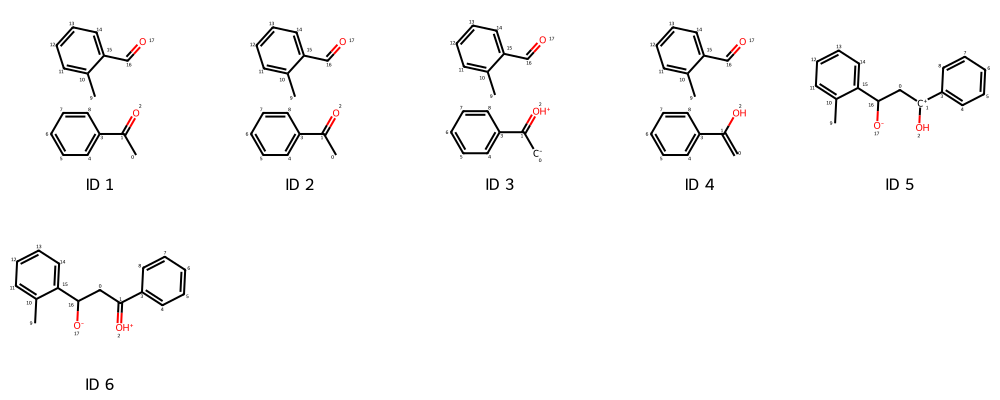

In [28]:
opt = Chem.Draw.MolDrawOptions()
opt.addAtomIndices = True
Chem.Draw.MolsToGridImage(mol_objects, molsPerRow=5, subImgSize=(200, 200), legends=[f"ID {i+1}" for i in range(len(mol_objects))], drawOptions=opt)